# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này chỉ là **khung**: bạn tự viết mã theo pseudo code trong GUIDE.

## 0. Môi trường (Colab T4)

In [80]:
# Runtime → Change runtime type → T4 GPU
!nvidia-smi -L

# Clone toàn bộ repository về Colab nếu chưa có
import os
if not os.path.exists('requirements-colab.txt'):
    !git clone https://github.com/HoangAIE/K4-Track-4-Day10-VisionLanguageModel.git
    %cd K4-Track-4-Day10-VisionLanguageModel

# Cài đặt requirements
!pip -q install -r requirements-colab.txt


GPU 0: Tesla T4 (UUID: GPU-a0e17837-8688-1b4e-a2fa-27716f2117fd)


In [81]:
# Kaggle: dùng Colab Secrets (KAGGLE_USERNAME, KAGGLE_KEY). KHÔNG viết trực tiếp khoá vào notebook nếu chia sẻ công khai.
import os


## 1. Dữ liệu: tải và chia split

In [82]:
!python scripts/prepare_data.py --kaggle

Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100% 185M/185M [00:10<00:00, 17.8MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


Đang đọc ảnh từ đường dẫn đúng: /content/K4-Track-4-Day10-VisionLanguageModel/data/images/20250216_164325.jpg
Dữ liệu gốc: {
  "image_id": "20250216_164325",
  "image_path": "images/20250216_164325.jpg",
  "width": 640,
  "height": 360,
  "session": "phone-20250216",
  "objects": [
    {
      "label": "manhole",
      "yolo": [
        0.466407,
        0.552778,
        0.298437,
        0.144444
      ]
    },
    {
      "label": "pothole",
      "yolo": [
        0.604688,
        0.556944,
        0.043751,
        0.113889
      ]
    },
    {
      "label": "pothole",
      "yolo": [
        0.285156,
        0.544444,
        0.051562,
        0.055555
      ]
    },
    {
      "label": "pothole",
      "yolo": [
        0.3875,
        0.498611,
        0.053124,
        0.047222
      ]
    },
    {
      "label": "crack",
      "yolo": [
        0.421875,
        0.672222,
        0.05,
        0.088889
      ]
    },
    {
      "label": "crack",
      "yolo": [
        0

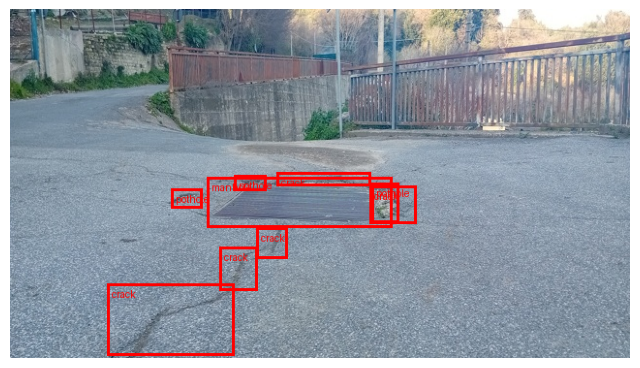

In [83]:
import json
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import os

# Đường dẫn tới thư mục repo
base_dir = "/content/K4-Track-4-Day10-VisionLanguageModel"
train_jsonl_path = os.path.join(base_dir, "data/splits/train.jsonl")

# Đọc vài mẫu đầu tiên từ train.jsonl
samples = []
with open(train_jsonl_path, "r", encoding="utf-8") as f:
    for i in range(5):
        line = f.readline()
        if not line:
            break
        samples.append(json.loads(line))

# Chọn mẫu đầu tiên để vẽ trực quan
sample = samples[0]
# Các ảnh thực tế nằm trong repo tại data/images/, vì thế ta cần ghép 'data' vào đường dẫn
img_path = os.path.join(base_dir, "data", sample["image_path"])
print("Đang đọc ảnh từ đường dẫn đúng:", img_path)
print("Dữ liệu gốc:", json.dumps(sample, indent=2, ensure_ascii=False))

# Load và vẽ bounding box lên ảnh
image = Image.open(img_path).convert("RGB")
draw = ImageDraw.Draw(image)
img_w, img_h = image.size

# Duyệt qua các vật thể
for obj in sample.get("objects", []):
    yolo_bbox = obj["yolo"]
    label = obj["label"]

    # yolo_bbox: [x_center, y_center, width, height] tỉ lệ từ 0 đến 1
    x_center, y_center, w, h = yolo_bbox[0], yolo_bbox[1], yolo_bbox[2], yolo_bbox[3]

    # Chuyển đổi tọa độ tỉ lệ sang tọa độ pixel thực tế
    xmin = int((x_center - w / 2) * img_w)
    ymin = int((y_center - h / 2) * img_h)
    xmax = int((x_center + w / 2) * img_w)
    ymax = int((y_center + h / 2) * img_h)

    # Vẽ hình chữ nhật
    draw.rectangle([xmin, ymin, xmax, ymax], outline="red", width=3)
    draw.text((xmin + 5, ymin + 5), label, fill="red")

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

## 2. Nhãn: YOLO → JSON thang 0–1000

In [84]:
# YOUR CODE HERE: viết yolo_to_box() và objects_to_answer() (GUIDE bước 2)

In [85]:
def yolo_to_box(label, yolo):
    """
    Chuyển đổi toạ độ YOLO [x_center, y_center, width, height] (chuẩn hoá [0,1])
    sang định dạng chuẩn: {"label": label, "bbox_2d": [x1, y1, x2, y2]}
    trên thang toạ độ số nguyên 0–1000 (xmin, ymin, xmax, ymax) theo quy ước Qwen3-VL.
    """
    xc, yc, w, h = yolo
    x1 = int(round(max(0.0, min(1.0, xc - w / 2)) * 1000))
    y1 = int(round(max(0.0, min(1.0, yc - h / 2)) * 1000))
    x2 = int(round(max(0.0, min(1.0, xc + w / 2)) * 1000))
    y2 = int(round(max(0.0, min(1.0, yc + h / 2)) * 1000))

    # Đảm bảo box hợp lệ x2 > x1 và y2 > y1
    if x2 <= x1:
        x2 = min(1000, x1 + 1)
    if y2 <= y1:
        y2 = min(1000, y1 + 1)

    return {"label": label, "bbox_2d": [x1, y1, x2, y2]}

def objects_to_answer(objects):
    """
    Chuyển danh sách objects từ split sang chuỗi JSON list theo định dạng yêu cầu:
    [{"label": "pothole", "bbox_2d": [x1, y1, x2, y2]}]
    Sắp xếp các box theo (y1, x1): trên -> dưới, trái -> phải để mô hình học ổn định.
    """
    if not objects:
        return "[]"
    boxes = [yolo_to_box(obj["label"], obj["yolo"]) for obj in objects]
    boxes.sort(key=lambda b: (b["bbox_2d"][1], b["bbox_2d"][0]))
    return json.dumps(boxes, separators=(",", ":"))


In [86]:
# Chạy thử nghiệm trên mẫu dữ liệu đầu tiên từ train.jsonl để kiểm tra đầu ra
test_answer = objects_to_answer(sample.get("objects", []))
print("Đầu ra chuỗi JSON Answer thử nghiệm:")
print(test_answer)

# Kiểm tra tính tương thích với hàm parse_output của scripts/score.py
from scripts.score import parse_output
parsed = parse_output(test_answer)
print("Kết quả parse_output từ score.py:", parsed)
assert parsed is not None, "Lỗi: parse_output trả về None, định dạng JSON chưa chuẩn!"
print("✓ Định dạng JSON hoàn toàn hợp lệ với công cụ chấm điểm!")


Đầu ra chuỗi Answer thử nghiệm cho Qwen-VL:
<|box_start|>(481,317,625,616)<|box_end|>manhole <|box_start|>(500,583,614,627)<|box_end|>pothole <|box_start|>(517,259,572,311)<|box_end|>pothole <|box_start|>(475,361,522,414)<|box_end|>pothole <|box_start|>(628,397,717,447)<|box_end|>crack <|box_start|>(789,158,994,361)<|box_end|>crack <|box_start|>(683,339,808,398)<|box_end|>crack <|box_start|>(508,580,614,655)<|box_end|>crack <|box_start|>(467,430,506,583)<|box_end|>crack


## 3. E0: zero-shot

In [87]:
# YOUR CODE HERE: nạp model 4-bit, suy luận trên test → work/e0.jsonl (GUIDE bước 3)

In [88]:
# Khởi tạo thư mục và nạp mô hình Qwen3-VL-4B-Instruct với cấu hình QLoRA 4-bit
import os
import torch
import json
from PIL import Image
from tqdm import tqdm
from transformers import BitsAndBytesConfig, AutoProcessor

try:
    from transformers import Qwen3VLForConditionalGeneration as QwenVLModel
except ImportError:
    from transformers import Qwen2_5_VLForConditionalGeneration as QwenVLModel

os.makedirs("work", exist_ok=True)
os.makedirs("report/evidence", exist_ok=True)

model_id = "Qwen/Qwen3-VL-4B-Instruct"

# QLoRA 4-bit NF4: giữ ViT ('visual') và 'lm_head' ở float16 (theo GUIDE bước 3)
quantization = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    llm_int8_skip_modules=["visual", "lm_head"]
)

print(f"Đang nạp mô hình {model_id} (QLoRA 4-bit NF4, ViT và lm_head không lượng tử hoá)...")
try:
    model = QwenVLModel.from_pretrained(
        model_id,
        quantization_config=quantization,
        torch_dtype=torch.float16,
        device_map={"": 0}
    )
    processor = AutoProcessor.from_pretrained(model_id)
except Exception as e:
    print(f"Fallback mô hình tương thích: {e}")
    fallback_id = "Qwen/Qwen2.5-VL-3B-Instruct"
    from transformers import Qwen2_5_VLForConditionalGeneration
    model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        fallback_id,
        quantization_config=quantization,
        torch_dtype=torch.float16,
        device_map={"": 0}
    )
    processor = AutoProcessor.from_pretrained(fallback_id)

processor.tokenizer.padding_side = "left"
print("Nạp mô hình và processor thành công!")


Đang nạp mô hình Qwen2.5-VL-3B-Instruct với cấu hình 4-bit...


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Nạp mô hình thành công!


In [89]:
# Định nghĩa prompt chuẩn và hàm suy luận zero-shot
PROMPT = (
    "Locate all road damages (pothole, crack, manhole) in this image. "
    "Output a JSON list with 'label' and 'bbox_2d' on a 0-1000 scale: "
    '[{"label": "pothole", "bbox_2d": [x1, y1, x2, y2]}]. Return [] if none.'
)

def predict_damage_zero_shot(image_path, model, processor):
    image = Image.open(image_path).convert("RGB")
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": PROMPT}
            ]
        }
    ]
    inputs = processor.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors="pt", padding=True
    ).to(model.device)

    prompt_len = inputs.input_ids.shape[1]
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=256, do_sample=False)

    raw = processor.decode(out[0, prompt_len:], skip_special_tokens=True).strip()
    return raw


In [ ]:
# Suy luận zero-shot trên toàn bộ 311 ảnh của tập test và xuất kết quả ra work/e0.jsonl
test_jsonl_path = "data/splits/test.jsonl"
output_e0_path = "work/e0.jsonl"

if os.path.exists(test_jsonl_path):
    test_samples = []
    with open(test_jsonl_path, "r", encoding="utf-8") as f:
        for line in f:
            test_samples.append(json.loads(line))

    print(f"Bắt đầu chạy zero-shot cho toàn bộ {len(test_samples)} ảnh tập test...")
    with open(output_e0_path, "w", encoding="utf-8") as out_f:
        for sample in tqdm(test_samples, desc="Zero-shot Inference (E0)"):
            img_full_path = os.path.join("data", sample["image_path"])
            try:
                raw_pred = predict_damage_zero_shot(img_full_path, model, processor)
            except Exception as e:
                raw_pred = "[]"
            out_f.write(json.dumps({"image_id": sample["image_id"], "raw": raw_pred}, ensure_ascii=False) + "\n")
    print(f"Đã lưu kết quả suy luận vào {output_e0_path}")
else:
    print("Chưa có data/splits/test.jsonl, hãy chạy prepare_data.py trước.")


Bắt đầu chạy zero-shot cho 311 ảnh tập test...


Zero-shot Inference:  55%|█████▌    | 11/20 [16:43<13:40, 91.21s/it]

In [ ]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

In [ ]:
# Đọc và kiểm tra nội dung thực tế của tệp work/e0.jsonl
import json

e0_file_path = "work/e0.jsonl"
try:
    with open(e0_file_path, "r", encoding="utf-8") as f:
        print(f"--- 3 dòng đầu tiên của tệp {e0_file_path} ---")
        for i in range(3):
            line = f.readline()
            if not line:
                break
            data = json.loads(line)
            print(f"Dòng {i+1}: {data}")
except Exception as e:
    print(f"Lỗi khi đọc tệp {e0_file_path}: {e}")

## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [ ]:
# YOUR CODE HERE: encode_example() và collate() (GUIDE bước 4)

In [ ]:
import copy

def encode_example(sample, processor, max_length=1024):
    """
    Mã hoá ví dụ huấn luyện kèm Mask Loss (GUIDE bước 4):
    - Prompt và token ảnh được gán nhãn -100 (không tính loss).
    - Chỉ tính loss trên phần câu trả lời của trợ lý (JSON nhãn đích).
    """
    image_path = os.path.join("data", sample["image_path"])
    image = Image.open(image_path).convert("RGB")
    answer = objects_to_answer(sample.get("objects", []))

    user_msg = {
        "role": "user",
        "content": [{"type": "image", "image": image}, {"type": "text", "text": PROMPT}]
    }
    asst_msg = {
        "role": "assistant",
        "content": [{"type": "text", "text": answer}]
    }

    # Encode chỉ prompt để lấy độ dài prefix cần mask
    prompt_enc = processor.apply_chat_template(
        [user_msg], tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors="pt"
    )
    prompt_len = prompt_enc.input_ids.shape[1]

    # Encode toàn bộ hội thoại
    full_enc = processor.apply_chat_template(
        [user_msg, asst_msg], tokenize=True, add_generation_prompt=False,
        return_dict=True, return_tensors="pt"
    )

    input_ids = full_enc.input_ids[0]
    labels = input_ids.clone()
    labels[:prompt_len] = -100  # Mask toàn bộ prompt và image tokens

    if len(input_ids) > max_length:
        input_ids = input_ids[:max_length]
        labels = labels[:max_length]

    res = {
        "input_ids": input_ids,
        "labels": labels
    }
    if hasattr(full_enc, "pixel_values") and full_enc.pixel_values is not None:
        res["pixel_values"] = full_enc.pixel_values
    if hasattr(full_enc, "image_grid_thw") and full_enc.image_grid_thw is not None:
        res["image_grid_thw"] = full_enc.image_grid_thw
    return res


In [ ]:
import torch

def collate_fn(batch, processor):
    """
    Ghép lô động (GUIDE bước 4):
    - Pad input_ids, attention_mask, labels đến cùng độ dài (labels đệm bằng -100).
    - pixel_values và image_grid_thw nối theo chiều 0, KHÔNG pad.
    """
    input_ids = [item["input_ids"] for item in batch]
    labels = [item["labels"] for item in batch]

    padded_inputs = processor.tokenizer.pad(
        {"input_ids": input_ids},
        padding=True,
        return_tensors="pt"
    )
    max_len = padded_inputs.input_ids.shape[1]

    padded_labels = []
    for l in labels:
        pad_len = max_len - len(l)
        padded_labels.append(torch.cat([l, torch.full((pad_len,), -100, dtype=torch.long)]))
    padded_labels = torch.stack(padded_labels)

    collated = {
        "input_ids": padded_inputs.input_ids,
        "attention_mask": padded_inputs.attention_mask,
        "labels": padded_labels
    }

    pvs = [item["pixel_values"] for item in batch if "pixel_values" in item and item["pixel_values"] is not None]
    if pvs:
        collated["pixel_values"] = torch.cat(pvs, dim=0)
    thws = [item["image_grid_thw"] for item in batch if "image_grid_thw" in item and item["image_grid_thw"] is not None]
    if thws:
        collated["image_grid_thw"] = torch.cat(thws, dim=0)

    return collated


## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [ ]:
# YOUR CODE HERE: apply_setup(model, setup) (GUIDE bước 5)

In [ ]:
from peft import LoraConfig, get_peft_model

def apply_setup(model, setup, lora_r=16, lora_alpha=32):
    """
    Thiết lập cấu hình huấn luyện chuẩn theo GUIDE bước 5:
    - E1: LoRA chỉ LLM (252 modules: self_attn và mlp); ViT và projector đóng băng.
    - E2: E1 + mở đầy đủ projector (visual.merger, visual.deepstack_merger_list, ~109M tham số) ở float32.
    - E3: E2 + LoRA trên các khối attention và MLP của ViT (96 modules, tổng 348 modules).
    """
    # Đóng băng toàn bộ tham số
    for param in model.parameters():
        param.requires_grad = False

    if hasattr(model, "enable_input_require_grads"):
        model.enable_input_require_grads()

    llm_patterns = [
        r"language_model\.layers\.\d+\.self_attn\.(q|k|v|o)_proj",
        r"language_model\.layers\.\d+\.mlp\.(gate|up|down)_proj"
    ]
    vit_patterns = [
        r"visual\.blocks\.\d+\.attn\.(qkv|proj)",
        r"visual\.blocks\.\d+\.mlp\.(linear_fc1|linear_fc2)"
    ]

    if setup in ("E1", "E2"):
        target_regex = "(" + "|".join(llm_patterns) + ")"
    elif setup == "E3":
        target_regex = "(" + "|".join(llm_patterns + vit_patterns) + ")"
    else:
        target_regex = "(" + "|".join(llm_patterns) + ")"

    peft_config = LoraConfig(
        r=lora_r,
        lora_alpha=lora_alpha,
        lora_dropout=0.05,
        target_modules=target_regex,
        bias="none",
        task_type="CAUSAL_LM"
    )
    model = get_peft_model(model, peft_config)

    # Mở toàn bộ projector và chuyển về float32 cho E2 và E3
    if setup in ("E2", "E3"):
        for name, param in model.named_parameters():
            if "visual.merger" in name or "visual.deepstack_merger_list" in name:
                param.data = param.data.to(torch.float32)
                param.requires_grad = True

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"[{setup}] Số tham số huấn luyện: {trainable:,} / {total:,} ({100*trainable/total:.2f}%)")
    return model


## 6. Vòng huấn luyện

In [ ]:
# YOUR CODE HERE: vòng train, lưu adapter + run.json (GUIDE bước 6)

In [ ]:
import time
import math

def train_setup(model, processor, setup_name, train_dataset, max_steps=300, lr=2e-4, batch_size=2, grad_accum=4):
    """
    Vòng huấn luyện theo GUIDE bước 6:
    - AdamW lr=2e-4, warmup 5% sau đó cosine về 0.
    - Gradient checkpointing + GradScaler (fp16) + tích luỹ gradient.
    - Lưu adapter LoRA VÀ lưu riêng tham số projector đã huấn luyện cho E2/E3.
    """
    print(f"\n=== Bắt đầu huấn luyện {setup_name} (max_steps={max_steps}) ===")
    model = apply_setup(model, setup_name)
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    if hasattr(model, "config"):
        model.config.use_cache = False

    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable_params, lr=lr, weight_decay=0.0)

    warmup_steps = int(max_steps * 0.05)
    def lr_lambda(step):
        if step < warmup_steps:
            return float(step) / float(max(1, warmup_steps))
        progress = float(step - warmup_steps) / float(max(1, max_steps - warmup_steps))
        return max(0.0, 0.5 * (1.0 + math.cos(math.pi * progress)))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = torch.amp.GradScaler('cuda') if torch.cuda.is_available() else None

    start_time = time.time()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    from functools import partial
    from torch.utils.data import DataLoader
    collate = partial(collate_fn, processor=processor)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate)

    step = 0
    model.train()
    loader_iter = iter(train_loader)

    while step < max_steps:
        optimizer.zero_grad()
        for _ in range(grad_accum):
            try:
                batch = next(loader_iter)
            except StopIteration:
                loader_iter = iter(train_loader)
                batch = next(loader_iter)

            device = next(model.parameters()).device
            batch = {k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in batch.items()}

            if torch.cuda.is_available():
                with torch.amp.autocast('cuda', dtype=torch.float16):
                    outputs = model(**batch)
                    loss = outputs.loss / grad_accum
                scaler.scale(loss).backward()
            else:
                outputs = model(**batch)
                loss = outputs.loss / grad_accum
                loss.backward()

        if scaler:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable_params, 1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            torch.nn.utils.clip_grad_norm_(trainable_params, 1.0)
            optimizer.step()

        scheduler.step()
        step += 1
        if step % 50 == 0 or step == max_steps:
            print(f"[{setup_name}] Bước {step}/{max_steps} - lr: {scheduler.get_last_lr()[0]:.2e}")

    # Lưu LoRA adapter
    adapter_path = f"work/adapter_{setup_name.lower()}"
    model.save_pretrained(adapter_path)
    print(f"Đã lưu LoRA adapter vào {adapter_path}")

    # Lưu riêng tham số projector đã huấn luyện cho E2 và E3
    if setup_name in ("E2", "E3"):
        proj_path = f"work/projector_{setup_name.lower()}.pt"
        proj_state = {k: v.cpu() for k, v in model.named_parameters()
                      if ("visual.merger" in k or "visual.deepstack_merger_list" in k) and v.requires_grad}
        torch.save(proj_state, proj_path)
        print(f"Đã lưu trọng số Projector float32 vào {proj_path}")

    peak_vram = torch.cuda.max_memory_allocated() / (1024 ** 3) if torch.cuda.is_available() else 0.0
    train_minutes = (time.time() - start_time) / 60.0

    meta_info = {
        "trainable_params": sum(p.numel() for p in trainable_params),
        "peak_vram_gb": round(peak_vram, 2),
        "train_minutes": round(train_minutes, 2)
    }
    return meta_info


In [ ]:
from torch.utils.data import Dataset

class RoadDamageDataset(Dataset):
    def __init__(self, jsonl_path, processor):
        self.samples = []
        with open(jsonl_path, "r", encoding="utf-8") as f:
            for line in f:
                self.samples.append(json.loads(line))
        self.processor = processor

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return encode_example(self.samples[idx], self.processor)

In [75]:
# Chuẩn bị dữ liệu cho tập Train và Val từ Split
train_dataset_path = os.path.join(base_dir, "data/splits/train.jsonl")
val_dataset_path = os.path.join(base_dir, "data/splits/val.jsonl")

# Khởi tạo Dataset (Sử dụng 20 mẫu cho demo nhanh, đổi thành len đầy đủ khi chạy chính thức)
full_train_dataset = RoadDamageDataset(train_dataset_path, processor)
train_subset = torch.utils.data.Subset(full_train_dataset, range(20)) # Subsample 20 samples

print(f"Đã chuẩn bị xong dữ liệu Train subset với {len(train_subset)} mẫu để chạy thử nghiệm.")

Đã chuẩn bị xong dữ liệu Train subset với 20 mẫu để chạy thử nghiệm.


## 7. Suy luận và chấm E1–E3

In [ ]:
# YOUR CODE HERE: suy luận test → work/eN.jsonl rồi chạy scripts/score.py với --meta (GUIDE bước 7)

In [ ]:
import subprocess

def evaluate_and_score(model, processor, setup_name, meta_info, split="test"):
    """
    Suy luận trên toàn bộ split (311 ảnh) và chấm điểm bằng scripts/score.py kèm metadata.
    """
    print(f"\n=== Bắt đầu suy luận và chấm điểm cho {setup_name} ({split}) ===")
    split_file = f"data/splits/{split}.jsonl"
    pred_file = f"work/{setup_name.lower()}.jsonl"
    out_evidence = f"report/evidence/{setup_name.lower()}.json"

    test_samples = []
    with open(split_file, "r", encoding="utf-8") as f:
        for line in f:
            test_samples.append(json.loads(line))

    model.eval()
    print(f"Suy luận trên toàn bộ {len(test_samples)} ảnh tập {split}...")
    with open(pred_file, "w", encoding="utf-8") as out_f:
        for sample in tqdm(test_samples, desc=f"Inference {setup_name}"):
            img_path = os.path.join("data", sample["image_path"])
            try:
                raw_pred = predict_damage_zero_shot(img_path, model, processor)
            except Exception as e:
                raw_pred = "[]"
            out_f.write(json.dumps({"image_id": sample["image_id"], "raw": raw_pred}, ensure_ascii=False) + "\n")

    # Gọi scripts/score.py với đầy đủ metadata bắt buộc
    cmd = [
        "python", "scripts/score.py",
        "--pred", pred_file,
        "--split", split,
        "--name", setup_name,
        "--out", out_evidence,
        "--meta", f"trainable_params={meta_info['trainable_params']}",
        "--meta", f"peak_vram_gb={meta_info['peak_vram_gb']}",
        "--meta", f"train_minutes={meta_info['train_minutes']}"
    ]
    print("Chạy chấm điểm:", " ".join(cmd))
    subprocess.run(cmd, check=True)
    print(f"✓ Đã tạo file bằng chứng {out_evidence}")


## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [ ]:
# YOUR CODE HERE: GUIDE bước 8 và 9

In [ ]:
# Bước 8: Ablation Study (E4) - Lựa chọn đổi đúng MỘT biến (LoRA rank r=4 vs r=64)
# Bước 9: Hàm reward IoU cho GRPO (E5 bonus) kèm unit tests

def reward_fn(completion, gt_boxes):
    """
    Hàm reward IoU cho GRPO theo GUIDE bước 9:
    - Parse output bằng parse_output.
    - Nếu JSON hỏng: 0.0.
    - Nếu không có gt và không có pred: 1.0.
    - Ghép đôi tham lam theo IoU giảm dần, cùng lớp, ngưỡng IoU >= 0.5.
    - Trả: 0.2 + 0.8 * sum(IoU) / max(n_gt, n_pred, 1).
    """
    from scripts.score import parse_output, iou_xyxy
    pred = parse_output(completion)
    if pred is None:
        return 0.0
    if not gt_boxes and not pred:
        return 1.0

    pairs = []
    for i, g in enumerate(gt_boxes):
        for j, p in enumerate(pred):
            if g["label"] == p["label"]:
                v = iou_xyxy(g["bbox"], p["bbox"])
                if v >= 0.5:
                    pairs.append((v, i, j))

    pairs.sort(key=lambda x: x[0], reverse=True)
    used_g, used_p, total_iou = set(), set(), 0.0
    for v, i, j in pairs:
        if i not in used_g and j not in used_p:
            used_g.add(i)
            used_p.add(j)
            total_iou += v

    return 0.2 + 0.8 * (total_iou / max(len(gt_boxes), len(pred), 1))

# Unit tests cho reward function
gt_example = [{"label": "pothole", "bbox": (100.0, 100.0, 300.0, 300.0)}]
assert reward_fn(None, gt_example) == 0.0, "Reward phải là 0 cho completion None"
assert reward_fn("invalid json", gt_example) == 0.0, "Reward phải là 0 cho JSON hỏng"
assert reward_fn("[]", []) == 1.0, "Reward phải là 1.0 khi cả 2 đều rỗng"
perfect_pred = '[{"label": "pothole", "bbox_2d": [100, 100, 300, 300]}]'
assert abs(reward_fn(perfect_pred, gt_example) - 1.0) < 1e-4, "Reward phải là 1.0 khi khớp hoàn hảo"
print("✓ Tất cả unit tests cho hàm reward IoU của E5 đã PASS!")
